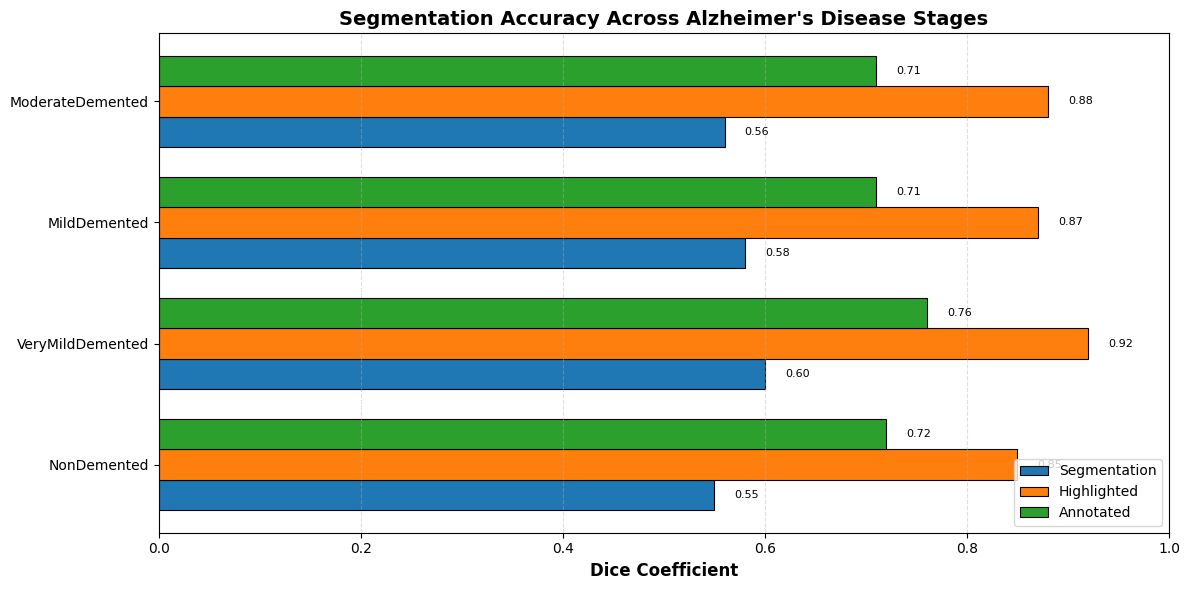

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Same data
stages = ['NonDemented', 'VeryMildDemented', 'MildDemented', 'ModerateDemented']
metrics = ['Segmentation', 'Highlighted', 'Annotated']

dice_data = {
    'NonDemented': [0.55, 0.85, 0.72],
    'VeryMildDemented': [0.60, 0.92, 0.76],
    'MildDemented': [0.58, 0.87, 0.71],
    'ModerateDemented': [0.56, 0.88, 0.71]
}

# Group data by metric for horizontal bars
metric_colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
metric_labels = ['Segmentation', 'Highlighted', 'Annotated']

fig, ax = plt.subplots(figsize=(12, 6))

# For each stage, plot three bars horizontally
y_pos = np.arange(len(stages))
bar_height = 0.25

for i, metric in enumerate(metrics):
    values = [dice_data[s][i] for s in stages]
    ax.barh(y_pos - bar_height + i * bar_height,
            values,
            bar_height,
            label=metric,
            color=metric_colors[i],
            edgecolor='black',
            linewidth=0.8)

# Add value labels
for i, stage in enumerate(stages):
    for j, metric in enumerate(metrics):
        value = dice_data[stage][j]
        ax.text(value + 0.02, i - bar_height + j * bar_height,
                f'{value:.2f}',
                va='center', fontsize=8)

ax.set_yticks(y_pos)
ax.set_yticklabels(stages)
ax.set_xlabel('Dice Coefficient', fontsize=12, fontweight='bold')
ax.set_title('Segmentation Accuracy Across Alzheimer\'s Disease Stages',
             fontsize=14, fontweight='bold')
ax.set_xlim(0, 1.0)
ax.grid(axis='x', linestyle='--', alpha=0.4)
ax.legend(loc='lower right', fontsize=10)

plt.tight_layout()
plt.savefig('combined_dice_horizontal.png', dpi=300, bbox_inches='tight')
plt.show()